# 01 · Análise exploratória das avaliações de clientes

**Tech Challenge – Fase 4 · Voice of Customer Intelligence com RAG**

Este notebook é a primeira etapa do projeto. Antes de construir a base de conhecimento do RAG, precisamos entender **o que existe nos comentários dos clientes**: quantos têm texto, como são escritos, onde há ruído, duplicatas e valores ausentes, e quais metadados ajudam a explicar a insatisfação.

Cada seção termina com uma **implicação para o projeto**. Quando havia mais de um caminho razoável, registramos também a **decisão avaliada**: as alternativas, os números que as sustentam e o motivo da escolha. A seção final reúne tudo nas decisões de preparo da base e lista as **técnicas de processamento de texto** usadas, onde e por quê.

| Seção | Pergunta |
| --- | --- |
| 1 | Quais tabelas usamos e como elas se relacionam? |
| 2 | Quem escreve comentários, e com que nota? Mantemos as avaliações que têm só título? |
| 3 | Qual o tamanho dos comentários? |
| 4 | Qual a qualidade do texto, e como normalizamos para comparar? |
| 5 | Como são os comentários reais? |
| 6 | Quais palavras distinguem insatisfeitos de satisfeitos? (*Bag of Words* e TF-IDF) |
| 7 | Há duplicatas ou problemas de integridade? |
| 8 | Quais valores estão ausentes? O que significa um pedido sem data de entrega? |
| 9 | Quais metadados explicam a insatisfação? Mantemos os pedidos sem itens? |
| 10 | O que decidimos, e com quais técnicas? |

### Principais achados

1. **Só 43% das avaliações têm texto, e as negativas comentam muito mais.** Cerca de 77% das notas 1 têm texto, contra 38% das notas 5. A base de texto é rica justamente em motivos de insatisfação.
2. **Comentários são curtos** (mediana de 53 caracteres) e **truncados em cerca de 200 caracteres** na origem. Uma avaliação = um documento, sem *chunking*.
3. **Cerca de 1 em cada 5 comentários é cópia de outro** ("muito bom", "ótimo"). São clientes distintos, mas as cópias poluiriam o top-k da busca vetorial.
4. **"Não" é a palavra que mais distingue as avaliações negativas** (aparece em 60% delas, contra 7% das positivas). Por isso a negação nunca é removida do texto, nem como *stopword*.
5. **TF-IDF não entende sentido:** para ele, "não recebi o produto" é 76% parecido com "recebi o produto". É o motivo de a busca do RAG usar **embeddings**, e o TF-IDF ficar na análise exploratória.
6. **A entrega é o metadado que mais separa satisfeitos de insatisfeitos.** Entregas no prazo têm 9% de avaliações negativas, e atrasadas, 62%. Nos pedidos que **nunca chegaram ao cliente**, a taxa vai de 69% (extraviados) a 88% (que nem saíram do vendedor).
7. **"Sem data de entrega" não é um grupo só.** Separamos pedidos entregues sem data registrada, enviados e não recebidos, não enviados e cancelados ou indisponíveis.
8. **Os nomes de lojas foram anonimizados** com casas de *Game of Thrones* ("lannister", "stark"…), citadas em cerca de 2 mil comentários.

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- Identidade visual dos gráficos -------------------------------------------
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
PRIMARY = "#2a78d6"  # medida única
# Nota 1→5 é polaridade (insatisfeito ↔ satisfeito): escala divergente
# vermelho ↔ cinza ↔ azul, com o neutro (nota 3) no centro.
SCORE_COLORS = {1: "#e34948", 2: "#f09a99", 3: "#d3d2ca", 4: "#86b6ef", 5: "#2a78d6"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 24,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.left": False,
})

def pct(x, total):
    return f"{x / total:.1%}".replace(".", ",")

def num(x):
    return f"{x:,.0f}".replace(",", ".")

def subtitle(ax, text):
    ax.text(0, 1.015, text, transform=ax.transAxes, color=INK_2, fontsize=9.5, va="bottom")

LABEL_BOX = dict(boxstyle="square,pad=0.15", facecolor=SURFACE, edgecolor="none")

def label_bars(ax, bars, labels):
    for bar, label in zip(bars, labels):
        ax.annotate(label, (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                    color=INK, fontsize=9)

## 1. Tabelas e relacionamentos

O foco do desafio são os comentários em `order_reviews`. As demais tabelas entram como **fontes de metadados** (entrega, categoria, período), que mais adiante servem para filtrar e contextualizar a recuperação.

```
order_reviews ──order_id──► orders ──order_id──► order_items ──product_id──► products ──► category_translation
  nota, título,               status, datas de        produto, vendedor,       categoria       nome em inglês
  comentário                  compra e entrega         preço, frete
```

In [2]:
reviews = pd.read_csv(RAW / "olist_order_reviews_dataset.csv",
                      parse_dates=["review_creation_date", "review_answer_timestamp"])
orders = pd.read_csv(RAW / "olist_orders_dataset.csv",
                     parse_dates=["order_purchase_timestamp", "order_approved_at",
                                  "order_delivered_carrier_date", "order_delivered_customer_date",
                                  "order_estimated_delivery_date"])
items = pd.read_csv(RAW / "olist_order_items_dataset.csv")
products = pd.read_csv(RAW / "olist_products_dataset.csv")
translation = pd.read_csv(RAW / "product_category_name_translation.csv", encoding="utf-8-sig")

tables = {"order_reviews": reviews, "orders": orders, "order_items": items,
          "products": products, "category_translation": translation}
pd.DataFrame({
    "linhas": {n: len(t) for n, t in tables.items()},
    "colunas": {n: t.shape[1] for n, t in tables.items()},
    "células ausentes (%)": {n: t.isna().mean().mean() * 100 for n, t in tables.items()},
})

,linhas,colunas,células ausentes (%)
order_reviews,99224,7,21.01
orders,99441,8,0.62
order_items,112650,7,0.00
products,32951,9,0.83
category_translation,71,2,0.00


In [3]:
reviews.isna().mean().mul(100).round(1).rename("% ausente").to_frame()

,% ausente
review_id,0.00
order_id,0.00
review_score,0.00
review_comment_title,88.30
review_comment_message,58.70
review_creation_date,0.00
review_answer_timestamp,0.00


Em `order_reviews`, **só a nota é sempre preenchida**. Título e comentário são opcionais e estão ausentes na maior parte das linhas. Por isso, o número real de documentos do RAG é bem menor que as 99 mil avaliações. A próxima seção mede esse número.

## 2. Quem escreve comentários, e com que nota?

In [4]:
has_title = reviews["review_comment_title"].fillna("").str.strip() != ""
has_msg = reviews["review_comment_message"].fillna("").str.strip() != ""
reviews["has_text"] = has_title | has_msg

combo = pd.Series({
    "título e comentário": (has_title & has_msg).sum(),
    "só comentário": (~has_title & has_msg).sum(),
    "só título": (has_title & ~has_msg).sum(),
    "nenhum texto": (~has_title & ~has_msg).sum(),
})
combo.to_frame("avaliações").assign(**{"%": combo / len(reviews) * 100})

,avaliações,%
título e comentário,9829,9.91
só comentário,31121,31.36
só título,1737,1.75
nenhum texto,56537,56.98


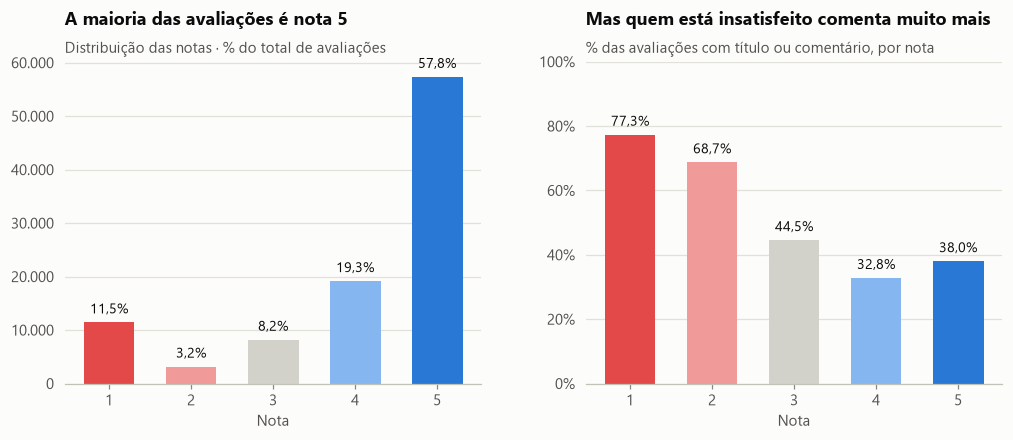

,avaliacoes,% com texto
review_score,,
1,11424,77.28
2,3151,68.71
3,8179,44.54
4,19142,32.78
5,57328,37.98


In [5]:
by_score = reviews.groupby("review_score").agg(avaliacoes=("review_id", "size"), com_texto=("has_text", "mean"))
total = by_score["avaliacoes"].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"wspace": 0.25})

ax = axes[0]
bars = ax.bar(by_score.index, by_score["avaliacoes"], width=0.62,
              color=[SCORE_COLORS[s] for s in by_score.index])
label_bars(ax, bars, [pct(v, total) for v in by_score["avaliacoes"]])
ax.set_title("A maioria das avaliações é nota 5")
subtitle(ax, "Distribuição das notas · % do total de avaliações")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: num(v)))
ax.set_xlabel("Nota")

ax = axes[1]
bars = ax.bar(by_score.index, by_score["com_texto"], width=0.62,
              color=[SCORE_COLORS[s] for s in by_score.index])
label_bars(ax, bars, [pct(v, 1) for v in by_score["com_texto"]])
ax.set_title("Mas quem está insatisfeito comenta muito mais")
subtitle(ax, "% das avaliações com título ou comentário, por nota")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 1)
ax.set_xlabel("Nota")
plt.show()

by_score.assign(com_texto=by_score["com_texto"] * 100).rename(columns={"com_texto": "% com texto"})

In [6]:
text_by_score = reviews[reviews["has_text"]].groupby("review_score").size()
display(Markdown(
    f"**{num(reviews['has_text'].sum())} avaliações têm algum texto** "
    f"({pct(reviews['has_text'].sum(), len(reviews))} da base). Dessas, "
    f"**{pct(text_by_score.loc[[1, 2]].sum(), text_by_score.sum())} são negativas (nota 1–2)**, "
    f"contra {pct(by_score.loc[[1, 2], 'avaliacoes'].sum(), total)} na base completa."
))

**42.687 avaliações têm algum texto** (43,0% da base). Dessas, **25,8% são negativas (nota 1–2)**, contra 14,7% na base completa.

**Leitura**
- **Avaliações negativas são sobrerrepresentadas entre as que têm texto.** Cerca de 3 em cada 4 notas 1 comentam, contra pouco mais de 1 em cada 3 notas 5. Para um projeto de *Voice of Customer*, isso é positivo: os motivos de insatisfação estão bem documentados.
- **O título carrega informação própria.** Cerca de 1.700 avaliações têm *só* título. Usar apenas o campo de comentário descartaria essas avaliações.

> **Implicação para o projeto**
> - O documento do RAG será **título + comentário**, e uma avaliação entra na base se tiver qualquer um dos dois.
> - Avaliações sem texto ficam fora da busca semântica, mas continuam úteis para estatísticas de nota.
> - Como os negativos estão sobrerrepresentados na base de texto, **frequências calculadas nos comentários não são proporções da base inteira**. As respostas não devem fazer essa extrapolação.

### 2.1 Decisão avaliada: excluir ou manter as avaliações que têm só título?

O grupo discutiu se as avaliações **sem comentário, só com título**, deveriam sair da análise. O argumento para excluir: títulos são curtíssimos ("recomendo", "ótimo") e acrescentariam pouca informação. Antes de decidir, medimos o tamanho e o perfil desse grupo.

In [7]:
only_title = reviews[has_title & ~has_msg]
with_msg = reviews[has_msg]
display(Markdown(
    f"- Avaliações **só com título**: {num(len(only_title))}, ou "
    f"**{pct(len(only_title), reviews['has_text'].sum())} das avaliações com texto** "
    f"({pct(len(only_title), len(reviews))} da base inteira).\n"
    f"- Metade dos títulos tem **até {only_title['review_comment_title'].str.split().str.len().median():.0f} palavra(s)**."
))
display(pd.DataFrame({
    "só título (%)": only_title["review_score"].value_counts(normalize=True) * 100,
    "com comentário (%)": with_msg["review_score"].value_counts(normalize=True) * 100,
}).sort_index().rename_axis("nota"))
(only_title.loc[only_title["review_score"] <= 2, "review_comment_title"]
 .sample(8, random_state=1).rename("títulos de avaliações negativas sem comentário").to_frame())

- Avaliações **só com título**: 1.737, ou **4,1% das avaliações com texto** (1,8% da base inteira).
- Metade dos títulos tem **até 1 palavra(s)**.

,só título (%),com comentário (%)
nota,,
1,4.89,21.35
2,1.15,5.24
3,5.01,8.68
4,17.50,14.58
5,71.45,50.15


,títulos de avaliações negativas sem comentário
66942,Não recebi o produto
38971,Não recebi até 28/04/20
45773,Bem tenhoqueteroproduto
91188,produto nao e original
43175,0
43250,Nao recomendo
56320,Não foi entregue
85487,muito ruim


**Leitura**
- O grupo é pequeno: cerca de 4% das avaliações com texto.
- Ele é **bem mais positivo** que as avaliações com comentário: cerca de 71% são nota 5, contra 51%.
- Mesmo curtos, os títulos negativos são **evidência direta**: "Não recebi o produto", "produto nao e original", "Não foi entregue".

> **Decisão: manter.** Avaliamos as duas alternativas:
>
> | | Excluir | Manter (escolhida) |
> | --- | --- | --- |
> | Viés | Retira sobretudo elogios de uma base que **já** é sobrerrepresentada em negativas (seção 2), distorcendo ainda mais o retrato do cliente | Preserva a distribuição real de quem escreveu algo |
> | Evidência | Perde reclamações objetivas ("não recebi o produto") | Cada título vira um documento rastreável pelo `review_id` |
> | Ruído | Elimina títulos genéricos | Títulos genéricos são tratados onde causam problema: marcação de **baixa informação** e **deduplicação na seleção das evidências** (seção 4) |
> | Custo | — | ~4% a mais de documentos, irrelevante para o índice |
>
> Excluir resolveria um problema de ruído **descartando dados legítimos**. Preferimos tratar o ruído na recuperação, onde ele de fato atrapalha, e manter na base tudo o que o cliente escreveu.

## 3. Qual o tamanho dos comentários?

O tamanho dos textos define se é preciso dividir os documentos (*chunking*). O modelo de embeddings escolhido, `multilingual-e5-base`, processa até 512 *tokens* por texto.

In [8]:
msg = reviews["review_comment_message"].dropna().str.strip()
msg = msg[msg != ""]
chars = msg.str.len()
words = msg.str.split().str.len()

pd.DataFrame({"caracteres": chars.describe(percentiles=[.1, .25, .5, .75, .9, .99]),
              "palavras": words.describe(percentiles=[.1, .25, .5, .75, .9, .99])}).T

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
caracteres,"40,950.00",68.40,53.83,1.00,12.00,28.00,53.00,94.00,160.00,200.00,208.00
palavras,"40,950.00",11.69,9.55,1.00,2.00,4.00,9.00,16.00,28.00,37.00,45.00


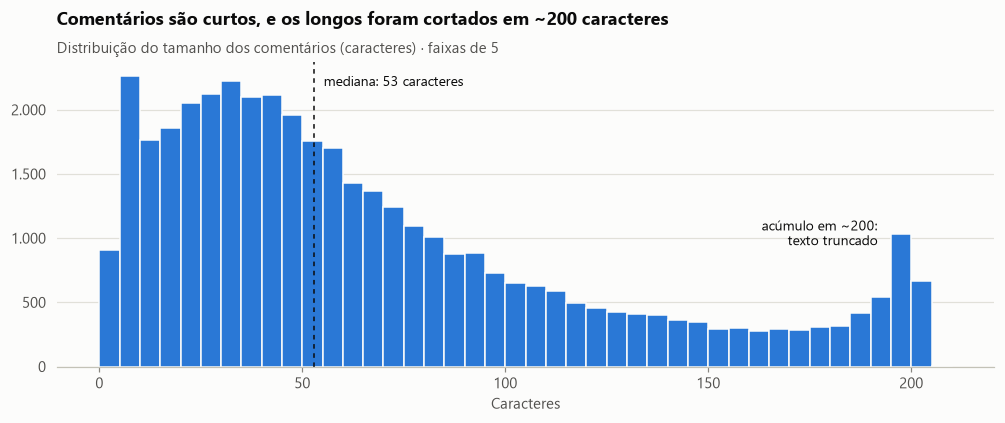

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.hist(chars, bins=range(0, 215, 5), color=PRIMARY, edgecolor=SURFACE, linewidth=1)
med = chars.median()
ax.axvline(med, color=INK, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate(f"mediana: {med:.0f} caracteres", (med, ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK, fontsize=9)
ax.annotate("acúmulo em ~200:\ntexto truncado", (200, 1030), xytext=(-22, 0), textcoords="offset points",
            ha="right", va="center", color=INK, fontsize=9)
ax.set_title("Comentários são curtos, e os longos foram cortados em ~200 caracteres")
subtitle(ax, "Distribuição do tamanho dos comentários (caracteres) · faixas de 5")
ax.set_xlabel("Caracteres")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: num(v)))
plt.show()

In [10]:
ends_punct = msg.str[-1].str.contains(r"[.!?)]", regex=True)
display(Markdown(
    f"- Comentários com **exatamente 200 caracteres**: {num((chars == 200).sum())}, contra "
    f"{num((chars == 190).sum())} com 190.\n"
    f"- Terminam com pontuação final: **{pct(ends_punct[chars == 200].sum(), (chars == 200).sum())}** dos que "
    f"têm 200 caracteres, contra {pct(ends_punct[chars.between(100, 189)].sum(), chars.between(100, 189).sum())} "
    f"dos que têm entre 100 e 189.\n\nFinal de alguns comentários com 200 caracteres:"))
msg[chars == 200].str[-50:].sample(5, random_state=3).rename("últimos 50 caracteres").to_frame()

- Comentários com **exatamente 200 caracteres**: 597, contra 78 com 190.
- Terminam com pontuação final: **35,0%** dos que têm 200 caracteres, contra 75,5% dos que têm entre 100 e 189.

Final de alguns comentários com 200 caracteres:

,últimos 50 caracteres
32278,a resposta convincente!!! Aguardo contato urgente!
76068,não era..por isso eu quero devolvê-lo e o estorno
18441,0.Eu queria ter esperado mais e nao ter pago frete
3133,uras e ao invés venho a navalha queria uma explica
85516,"rio de atendimento é ridículo, só vagabundo pra ir"


**Leitura**
- Metade dos comentários tem até cerca de 53 caracteres, ou 9 palavras.
- **Há um acúmulo anormal em ~200 caracteres, com textos terminando no meio da palavra.** Os comentários foram truncados na origem, provavelmente por um limite do formulário. Não é possível recuperar o trecho perdido.
- Mesmo o maior comentário fica muito abaixo do limite de 512 *tokens* do modelo de embeddings.

> **Implicação para o projeto: sem *chunking*. Cada avaliação vira um documento.**
> - Dividir textos tão curtos só fragmentaria o sentido.
> - Agrupar várias avaliações num mesmo documento misturaria clientes, notas e pedidos diferentes e quebraria a rastreabilidade da evidência. O desafio exige justamente essa rastreabilidade.
> - O truncamento é uma **limitação da base**, a ser declarada na documentação: em relatos longos, o desfecho pode ter sido cortado.

## 4. Qualidade do texto

Avaliamos três aspectos:
- comentários curtos demais para servir de evidência;
- textos repetidos;
- ruídos de digitação.

Para saber se dois comentários são "o mesmo texto", não basta comparar as *strings*: "Ótimo!", "otimo" e "ÓTIMO" seriam três textos diferentes. Por isso usamos uma **normalização de comparação** (`normalize_for_count`), em quatro passos:

| Passo | Técnica | Exemplo |
| --- | --- | --- |
| 1 | **Minúsculas** (*case folding*, `.lower()`) | "ÓTIMO" → "ótimo" |
| 2 | **Remoção de acentos**: decomposição Unicode NFKD, que separa a letra do acento, e descarte dos acentos | "ótimo" → "otimo" |
| 3 | **Remoção de pontuação e símbolos** (regex `[^\w\s]`) | "otimo!!!" → "otimo" |
| 4 | **Colapso de espaços** (regex `\s+`) | "muito   bom" → "muito bom" |

Essa versão do texto serve **só para contar e comparar**. O texto que vai para o índice do RAG mantém caixa, acentos e pontuação (ver a implicação desta seção e a seção 10).

In [11]:
def normalize_for_count(text: str) -> str:
    # Minúsculas, sem acentos e sem pontuação: só para COMPARAR textos, nunca para indexar.
    text = unicodedata.normalize("NFKD", text.lower())
    text = "".join(c for c in text if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", text)).strip()

norm = msg.map(normalize_for_count)
counts = norm.value_counts()

display(Markdown(
    f"- Comentários com **até 3 caracteres**: {num((chars <= 3).sum())} · com **até 10**: {num((chars <= 10).sum())}\n"
    f"- Textos distintos (após normalizar): **{num(norm.nunique())} de {num(len(norm))}**\n"
    f"- {num((counts >= 2).sum())} textos aparecem mais de uma vez e somam "
    f"**{num(counts[counts >= 2].sum())} comentários** ({pct(counts[counts >= 2].sum(), len(norm))})"
))
counts.rename(index={"": "(só pontuação ou símbolos)"}).head(15).rename("ocorrências").to_frame()

- Comentários com **até 3 caracteres**: 809 · com **até 10**: 3.644
- Textos distintos (após normalizar): **33.481 de 40.950**
- 1.301 textos aparecem mais de uma vez e somam **8.770 comentários** (21,4%)

,ocorrências
review_comment_message,
muito bom,598
otimo,471
bom,369
recomendo,316
excelente,214
otimo produto,168
ok,158
tudo ok,131
(só pontuação ou símbolos),123


In [12]:
noise = {
    "quebra de linha": msg.str.contains(r"[\r\n]", regex=True),
    "pontuação repetida (!!!, ???, ...)": msg.map(lambda s: bool(re.search(r"([!?.])\1{2,}", s))),
    "todo em caixa alta": msg.map(lambda s: s.isupper()),
    "emoji": msg.map(lambda s: bool(re.search("[\U0001F300-\U0001FAFF☀-➿]", s))),
    "link (http)": msg.str.contains("http", regex=False),
}
pd.DataFrame({"comentários": {k: v.sum() for k, v in noise.items()},
              "%": {k: v.mean() * 100 for k, v in noise.items()}})

,comentários,%
quebra de linha,2710,6.62
"pontuação repetida (!!!, ???, ...)",2875,7.02
todo em caixa alta,1294,3.16
emoji,273,0.67
link (http),1,0.00


In [13]:
# Grafias originais que a normalização de comparação reduz a "otimo" ou "otimo produto"
spellings = msg[norm.isin(["otimo", "otimo produto"])]
(spellings.value_counts().rename("ocorrências").to_frame()
 .assign(normalizado=lambda d: d.index.map(normalize_for_count)).head(12))

,ocorrências,normalizado
review_comment_message,,
Ótimo,158,otimo
otimo,108,otimo
Otimo,107,otimo
Ótimo produto,67,otimo produto
ótimo,32,otimo
Ótimo produto.,22,otimo produto
otimo produto,17,otimo produto
Otimo produto,13,otimo produto
Ótimo produto!,13,otimo produto


### 4.1 Nomes de lojas anonimizados

Ao ler os comentários, aparecem palavras como "lannister" e "targaryen". A Olist anonimizou os nomes das empresas parceiras trocando-os por casas de *Game of Thrones*.

In [14]:
houses = ["lannister", "stark", "baratheon", "targaryen"]
lower = msg.str.lower()
mentions = pd.Series({h: lower.str.contains(rf"\b{h}\b", regex=True).sum() for h in houses}, name="comentários")
display(mentions.to_frame())
msg[lower.str.contains("lannister", regex=False)].sample(4, random_state=7).rename("exemplos").to_frame()

,comentários
lannister,1207
stark,305
baratheon,275
targaryen,272


,exemplos
32050,A loja lannister sempre atendeu as minhas expectativas no que diz respeito a qualidade do produto e prazo de entrega.
57848,"Comprei 5 itens, me chega 1 item que nem rastreio tem no site lannister e o vendedor vêm me perguntar se recebi o lo..."
69797,Sempre confiei nas redes lannister 👍🏻
28397,o protuto chegou corretamente. eu recomendo as lojas lannister. muito obrigado...


**Leitura**
- **Repetição é alta.** Cerca de 1 em cada 5 comentários é idêntico a outro: "muito bom", "recomendo", "ótimo"…
  - Na busca vetorial, isso faria os primeiros resultados de uma pergunta sobre elogios virem cheios de cópias do mesmo texto, sem acrescentar nenhuma evidência nova.
  - Essas repetições, porém, são **avaliações legítimas de clientes diferentes**: não são erro de dados.
- **Grafias variam em acento, caixa e pontuação.** "ótimo" e "otimo" aparecem quase na mesma proporção, ao lado de "Ótimo", "ÓTIMO" e "Otimo!". A normalização de comparação reduz todas a um só texto.
- **O ruído é pequeno e superficial:** quebras de linha, pontuação repetida e caixa alta. Emojis e links são raros.
- **Lojas aparecem com nomes fictícios.** Cerca de 2 mil comentários citam uma "casa", e "lannister" é de longe a mais frequente.

> **Implicação para o projeto**
> - **Limpeza leve:** normalizar espaços e quebras de linha e reduzir pontuação repetida, **preservando acentos, emojis e caixa no texto indexado**. O modelo E5 foi treinado com texto natural, e "PÉSSIMO!!!" carrega intensidade que não deve ser apagada.
> - **Não remover duplicatas da base**, porque cada cópia é um cliente. A deduplicação será feita **na seleção das evidências**, comparando textos normalizados.
> - **Comentários sem conteúdo** (".", "ok", "10") serão marcados como de baixa informação, com um limiar a definir na etapa de preparo.
> - **Nomes anonimizados ficam no texto** (são parte do relato), mas o prompt do LLM vai explicar que são **pseudônimos de lojas**, para que a resposta não os apresente como empresas reais.

## 5. Como são os comentários reais?

Uma amostra aleatória (semente fixa) de comentários com mais de 40 caracteres, por nota, para dar uma ideia concreta do vocabulário dos clientes.

In [15]:
sample = (reviews[reviews["review_comment_message"].fillna("").str.len() > 40]
          .groupby("review_score", group_keys=False)
          .sample(3, random_state=42)[["review_score", "review_comment_title", "review_comment_message"]]
          .rename(columns={"review_score": "nota", "review_comment_title": "título",
                           "review_comment_message": "comentário"}))
sample.fillna("—").style.hide(axis="index").set_properties(**{"text-align": "left"})

nota,título,comentário
1,—,"O frete é caro e ainda se quiser tem q buscar no correio.Muito ruim.Ainda quer elogios,odiei."
1,—,"Essa foi a pior compra da minha vida, comprei dia 11/6/17 para receber dia 05/07/17 e até hoje não recebi e ninguém me ligou para dar uma satisfação. A pior comprar da minha vida."
1,—,"No sate falava que era Sony com case , chegou um que não é Sony e nem veio a Case, tomem cuidado com esse fornecedor promete uma coisa e manda outra."
2,—,Comprei um jogo de cama lençol e recebi um cobre leito
2,—,"Recebi o produto, na verdade comprei a case para um tablet 10.1 e não serviu, então as medidas dessa case não deve estar correta."
2,—,"ENTREGARAM UMA COQUETELEIRA DIFERENTE DO ANUNCIO, TUDO SUJA EMPOEIRADA E QUE VAZA UM MONTE DE WHEY DURANTE A MISTURA !"
3,—,"O produto foi entregue dentro do prazo, entretanto, não veio na embalagem original. Veio dentro de um saco plástico bem simples."
3,—,O produto esta em processo de devolução e foi entregue no lugar errado para qualquer pessoa. Logo o processo de devolução será demorado.
3,—,Ainda não recebi o meu produto. Quando receber posso recomendar a loja para todos!!!!
4,—,"Meu produto chegou, mas veio solto dentro da caixa e com amassamento na tampa do espremedor"


**Leitura:** nas notas baixas, os temas aparecem de forma explícita: produto não recebido, atraso, produto errado ou com defeito, falta de resposta do vendedor. Nas notas altas, o elogio costuma vir junto com a **entrega no prazo**. A logística aparece nos dois extremos, o que a seção 9 confirma com números.

## 6. Quais palavras distinguem insatisfeitos de satisfeitos? *Bag of Words* e TF-IDF

As seções anteriores leram comentários um a um. Aqui **quantificamos o vocabulário** com duas técnicas clássicas de representação de texto.

**Bag of Words (BoW, "saco de palavras").** Cada documento vira um vetor de contagens, com uma posição para cada termo do vocabulário. A ordem das palavras é ignorada: só importa quantas vezes cada termo aparece. É simples e transparente, mas trata todas as palavras como igualmente importantes.

**TF-IDF (*Term Frequency × Inverse Document Frequency*).** Pondera a contagem pela **raridade** do termo na base:

$$\text{tfidf}(t, d) = \underbrace{\text{tf}(t, d)}_{\text{vezes que } t \text{ aparece em } d} \times \underbrace{\left(\ln\frac{1 + N}{1 + \text{df}(t)} + 1\right)}_{\text{idf: maior quanto mais raro é } t}$$

em que $N$ é o número de documentos e $\text{df}(t)$ é quantos deles contêm $t$. Um termo presente em quase todo documento ("produto") recebe peso baixo, e um termo concentrado em poucos ("atraso", "lannister") recebe peso alto. Cada vetor é então normalizado (norma L2), para que comentários longos não pesem mais só por serem longos.

O exemplo abaixo mostra as duas representações para três avaliações curtas.

In [16]:
toy = ["Produto chegou rápido, recomendo", "Não chegou o produto", "Produto ótimo, chegou antes do prazo"]
toy_norm = [normalize_for_count(t) for t in toy]
toy_index = [f"doc {i + 1}: {t}" for i, t in enumerate(toy)]

bow_toy = CountVectorizer().fit(toy_norm)
tfidf_toy = TfidfVectorizer().fit(toy_norm)
display(Markdown("**Bag of Words:** contagem de cada termo em cada documento"))
display(pd.DataFrame(bow_toy.transform(toy_norm).toarray(), index=toy_index,
                     columns=bow_toy.get_feature_names_out()))
display(Markdown("**TF-IDF:** \"produto\" e \"chegou\" estão nos três documentos e recebem os menores pesos de cada linha"))
pd.DataFrame(tfidf_toy.transform(toy_norm).toarray(), index=toy_index,
             columns=tfidf_toy.get_feature_names_out()).round(2)

**Bag of Words:** contagem de cada termo em cada documento

,antes,chegou,do,nao,otimo,prazo,produto,rapido,recomendo
"doc 1: Produto chegou rápido, recomendo",0,1,0,0,0,0,1,1,1
doc 2: Não chegou o produto,0,1,0,1,0,0,1,0,0
"doc 3: Produto ótimo, chegou antes do prazo",1,1,1,0,1,1,1,0,0


**TF-IDF:** "produto" e "chegou" estão nos três documentos e recebem os menores pesos de cada linha

,antes,chegou,do,nao,otimo,prazo,produto,rapido,recomendo
"doc 1: Produto chegou rápido, recomendo",0.00,0.36,0.00,0.00,0.00,0.00,0.36,0.61,0.61
doc 2: Não chegou o produto,0.00,0.45,0.00,0.77,0.00,0.00,0.45,0.00,0.00
"doc 3: Produto ótimo, chegou antes do prazo",0.46,0.27,0.46,0.00,0.46,0.46,0.27,0.00,0.00


### 6.1 Pré-processamento para BoW e TF-IDF

Estas técnicas contam palavras, então o texto precisa ser padronizado antes. Esse pré-processamento vale **só para esta análise**: o texto indexado no RAG não passa por ele (seção 10).

1. **Normalização de comparação** da seção 4: minúsculas, sem acentos, sem pontuação.
2. **Tokenização por palavras** com 2 ou mais caracteres (padrão do `scikit-learn`).
3. **Remoção de *stopwords*** (palavras muito frequentes e sem conteúdo, como "de", "para", "que"), com uma **lista própria**. Listas prontas em português, como a do NLTK, incluem **"não"**. Removê-lo faria "chegou" e "não chegou" virarem o mesmo termo, o que é inaceitável numa análise de satisfação. Por isso negações ("nao", "nem", "nunca") e palavras de intensidade ("muito") ficam fora da lista.
4. **Unigramas e bigramas** (`ngram_range=(1, 2)`): além de palavras isoladas, pares de palavras vizinhas, como "nao recebi" e "antes prazo".
5. **Frequência mínima** (`min_df=5`): termos presentes em menos de 5 documentos são descartados, o que elimina erros de digitação raros.

**Não usamos *stemming* nem lematização** (reduzir "recebi", "recebido" e "receber" a um radical comum). Com textos tão curtos, o ganho de agrupamento é pequeno, e os termos ficariam menos legíveis ("receb" em vez de "recebi").

O corpus é uma avaliação por `review_id` com título ou comentário, com os dois campos concatenados, como será o documento do RAG. Comparamos **negativas** (nota 1–2) e **positivas** (nota 4–5). A nota 3 fica fora da comparação.

Matriz BoW: **42.370 documentos × 10.178 termos** (unigramas e bigramas), com 0,1% das células preenchidas. Uma matriz quase toda de zeros, ou **esparsa**, é típica do BoW: cada comentário usa pouquíssimas palavras do vocabulário.

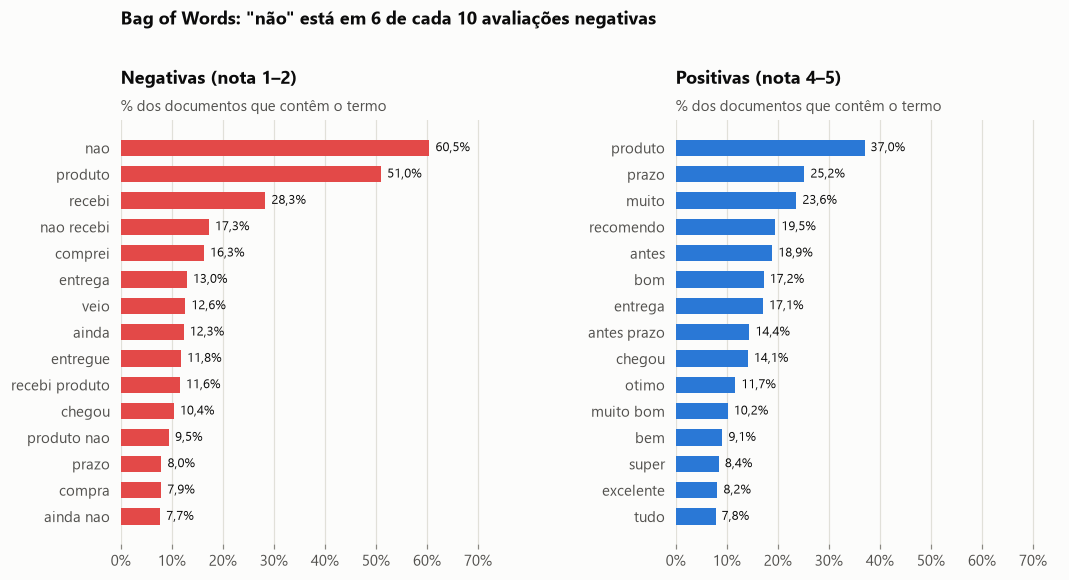

In [17]:
# Lista própria de stopwords, já normalizada (sem acentos). Negações ("nao", "nem", "nunca"),
# "sem", "ainda" e "muito" ficam FORA da lista de propósito: carregam o sentido da avaliação.
STOPWORDS_PT = """
de da do das dos em na no nas nos um uma uns umas para pra pro por pelo pela pelos pelas com que se ao aos as os
me eu meu minha meus minhas voce voces vc ele ela eles elas isso isto esse essa este esta esses essas aquele aquela
foi ser era sao estava estou sou tem ter tinha ja mas tambem so ou como quando ate lhe seu sua seus suas pois porque
entao aqui la ai sobre entre
""".split()

docs = reviews.drop_duplicates("review_id").loc[lambda d: d["has_text"]]
corpus = (docs["review_comment_title"].fillna("") + " " + docs["review_comment_message"].fillna("")).map(normalize_for_count)
is_neg = (docs["review_score"] <= 2).to_numpy()
is_pos = (docs["review_score"] >= 4).to_numpy()

bow = CountVectorizer(stop_words=STOPWORDS_PT, ngram_range=(1, 2), min_df=5)
X_bow = bow.fit_transform(corpus)
# % dos documentos de cada grupo que contêm o termo ao menos uma vez
present = X_bow > 0
doc_share = pd.DataFrame({"negativas": present[is_neg].mean(axis=0).A1,
                          "positivas": present[is_pos].mean(axis=0).A1},
                         index=bow.get_feature_names_out())

display(Markdown(
    f"Matriz BoW: **{num(X_bow.shape[0])} documentos × {num(X_bow.shape[1])} termos** (unigramas e bigramas), "
    f"com {pct(X_bow.nnz, X_bow.shape[0] * X_bow.shape[1])} das células preenchidas. Uma matriz quase toda de zeros, "
    f"ou **esparsa**, é típica do BoW: cada comentário usa pouquíssimas palavras do vocabulário."
))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"wspace": 0.45})
for ax, group, color, title in [(axes[0], "negativas", SCORE_COLORS[1], "Negativas (nota 1–2)"),
                                (axes[1], "positivas", SCORE_COLORS[5], "Positivas (nota 4–5)")]:
    top = doc_share[group].nlargest(15)[::-1]
    bars = ax.barh(top.index, top.values, height=0.62, color=color)
    for bar, v in zip(bars, top.values):
        ax.annotate(pct(v, 1), (bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(4, 0),
                    textcoords="offset points", va="center", color=INK, fontsize=8.5)
    ax.set_title(title)
    subtitle(ax, "% dos documentos que contêm o termo")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, 0.75)
    ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
    ax.spines["bottom"].set_visible(False)
fig.suptitle("Bag of Words: \"não\" está em 6 de cada 10 avaliações negativas", x=0.125, ha="left",
             fontsize=12, fontweight="bold", color=INK, y=1.08)
plt.show()

O BoW mostra os termos **mais frequentes**, mas alguns aparecem no topo dos dois grupos ("produto", "entrega", "chegou"). Para encontrar o que é **característico** de cada grupo, usamos o TF-IDF e comparamos o peso médio de cada termo nas negativas e nas positivas.

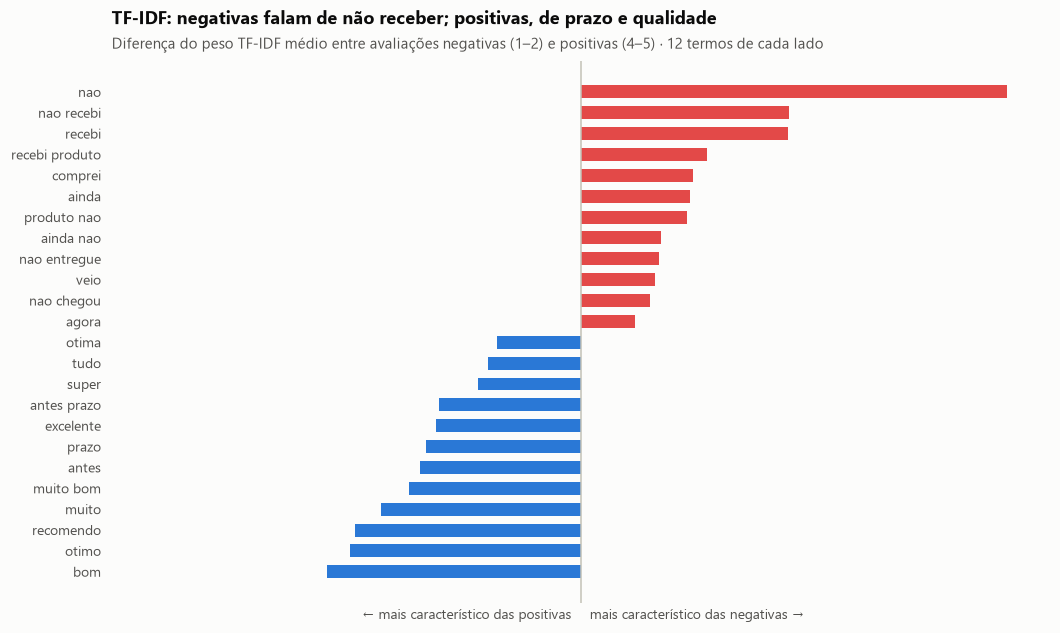

,negativas,positivas,diferença
nao,0.0892,0.0076,0.0816
nao recebi,0.0406,0.0007,0.0399
recebi,0.0484,0.0087,0.0397
recebi produto,0.0279,0.0038,0.0241
comprei,0.0245,0.0030,0.0214
ainda,0.0250,0.0041,0.0210
produto nao,0.0213,0.0009,0.0204
ainda nao,0.0179,0.0025,0.0154
nao entregue,0.0153,0.0003,0.0149
veio,0.0210,0.0067,0.0142


In [18]:
tfidf = TfidfVectorizer(stop_words=STOPWORDS_PT, ngram_range=(1, 2), min_df=5)
X_tfidf = tfidf.fit_transform(corpus)
weights = pd.DataFrame({"negativas": X_tfidf[is_neg].mean(axis=0).A1,
                        "positivas": X_tfidf[is_pos].mean(axis=0).A1},
                       index=tfidf.get_feature_names_out())
weights["diferença"] = weights["negativas"] - weights["positivas"]
distinct = pd.concat([weights.nsmallest(12, "diferença"), weights.nlargest(12, "diferença")[::-1]])

fig, ax = plt.subplots(figsize=(11, 6.4))
colors = [SCORE_COLORS[1] if d > 0 else SCORE_COLORS[5] for d in distinct["diferença"]]
ax.barh(distinct.index, distinct["diferença"], height=0.62, color=colors)
ax.axvline(0, color=AXIS, linewidth=1)
lim = distinct["diferença"].abs().max() * 1.1
ax.set_xlim(-lim, lim)
ax.annotate("← mais característico das positivas", (0, 0), xycoords=("data", "axes fraction"), xytext=(-6, -4),
            textcoords="offset points", ha="right", va="top", color=INK_2, fontsize=9)
ax.annotate("mais característico das negativas →", (0, 0), xycoords=("data", "axes fraction"), xytext=(6, -4),
            textcoords="offset points", ha="left", va="top", color=INK_2, fontsize=9)
ax.set_title("TF-IDF: negativas falam de não receber; positivas, de prazo e qualidade")
subtitle(ax, "Diferença do peso TF-IDF médio entre avaliações negativas (1–2) e positivas (4–5) · 12 termos de cada lado")
ax.set_xticks([])
ax.grid(axis="y", visible=False)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", labelsize=9)
plt.show()
weights.loc[distinct.index[::-1]].style.format("{:.4f}")

### 6.2 Por que BoW e TF-IDF não são a busca do RAG?

As duas técnicas comparam **palavras**, não **sentido**. Um teste simples mostra o problema: medimos a similaridade de cosseno entre os vetores TF-IDF de três frases.

In [19]:
phrases = ["Não recebi o produto", "O pedido não chegou", "Recebi o produto"]
sim = cosine_similarity(tfidf.transform([normalize_for_count(p) for p in phrases]))
pd.DataFrame(sim, index=phrases, columns=phrases).round(2)

,Não recebi o produto,O pedido não chegou,Recebi o produto
Não recebi o produto,1.00,0.08,0.76
O pedido não chegou,0.08,1.00,0.00
Recebi o produto,0.76,0.00,1.00


**Leitura**
- **O vocabulário confirma os temas da leitura manual.** As negativas giram em torno de **não receber** ("nao recebi", "ainda nao", "nao entregue", "nao chegou") e de **receber errado** ("veio"). As positivas falam de **prazo** ("antes prazo") e de **qualidade** ("otimo", "excelente", "recomendo").
- **"nao" é o termo mais discriminante da base.** Manter as negações fora da lista de *stopwords* foi decisivo: com uma lista pronta, esse sinal teria sido apagado.
- **TF-IDF não entende sentido.** "Não recebi o produto" e "Recebi o produto" têm **sentidos opostos**, mas para o TF-IDF são muito parecidas, porque compartilham "recebi" e "produto". Já "O pedido não chegou", que diz **a mesma coisa** que a primeira frase, quase não tem palavras em comum com ela e fica com similaridade perto de zero.

> **Implicação para o projeto**
> - **BoW e TF-IDF ficam na análise exploratória**, onde são transparentes e explicáveis: mostram *quais palavras* separam os grupos.
> - **A busca do RAG usa embeddings densos** (`multilingual-e5-base`). Eles representam o **sentido** da frase: "não recebi" e "não chegou" ficam próximos, e a negação muda o vetor.
> - **Busca lexical na fase 2:** o BM25, um sucessor do TF-IDF, pode complementar os embeddings numa busca híbrida, para termos exatos que os embeddings tendem a diluir (por exemplo "lannister" ou nomes de categorias).

## 7. Duplicatas e integridade

In [20]:
dup_review = reviews["review_id"].duplicated(keep=False)
integrity = pd.Series({
    "linhas em order_reviews": len(reviews),
    "review_id distintos": reviews["review_id"].nunique(),
    "linhas com review_id repetido": dup_review.sum(),
    "pares (review_id, order_id) repetidos": reviews.duplicated(["review_id", "order_id"]).sum(),
    "pedidos com mais de uma avaliação": (reviews["order_id"].value_counts() > 1).sum(),
    "avaliações sem pedido correspondente": (~reviews["order_id"].isin(orders["order_id"])).sum(),
    "pedidos sem itens": (~orders["order_id"].isin(items["order_id"])).sum(),
}, name="quantidade")
integrity.to_frame()

,quantidade
linhas em order_reviews,99224
review_id distintos,98410
linhas com review_id repetido,1603
"pares (review_id, order_id) repetidos",0
pedidos com mais de uma avaliação,547
avaliações sem pedido correspondente,0
pedidos sem itens,775


In [21]:
example_id = reviews.loc[dup_review & has_msg, "review_id"].iloc[0]
reviews.loc[reviews["review_id"] == example_id,
            ["review_id", "order_id", "review_score", "review_comment_message"]]

,review_id,order_id,review_score,review_comment_message
346,f4d74b17cd63ee35efa82cd2567de911,f269e83a82f64baa3de97c2ebf3358f6,3,"A embalagem deixou a desejar, por pouco o produto não foi danificado, a caixa estava toda amassada."
90298,f4d74b17cd63ee35efa82cd2567de911,a60c9bf6dcdd39e9f1c10ae5ad77c24d,3,"A embalagem deixou a desejar, por pouco o produto não foi danificado, a caixa estava toda amassada."


**Leitura**
- **O mesmo `review_id` aparece ligado a pedidos diferentes, com o mesmo texto.** É um comportamento conhecido da base Olist: uma única avaliação vale para vários pedidos do mesmo cliente.
  - Não há linhas inteiramente duplicadas.
  - Indexar cada linha criaria documentos repetidos com o mesmo identificador.
- **A integridade referencial está boa:** toda avaliação tem pedido correspondente.

> **Implicação para o projeto**
> - **Uma linha por `review_id`**, mantendo a primeira ocorrência. Assim o `review_id` vira o identificador único da evidência, que é o que o usuário vê ao rastrear uma resposta.
> - **Junção com outras tabelas sempre com `how="left"`.** Pedidos sem itens não podem derrubar avaliações.

## 8. Valores ausentes nas tabelas de apoio

In [22]:
missing = pd.Series({
    "produtos sem categoria": products["product_category_name"].isna().sum(),
    "categorias sem tradução": len(set(products["product_category_name"].dropna())
                                   - set(translation["product_category_name"])),
    "pedidos sem data de entrega ao cliente": orders["order_delivered_customer_date"].isna().sum(),
    "  ↳ dos quais com status 'delivered'": (orders["order_delivered_customer_date"].isna()
                                             & (orders["order_status"] == "delivered")).sum(),
}, name="quantidade")
display(missing.to_frame())
print("Categorias sem tradução:", sorted(set(products["product_category_name"].dropna())
                                         - set(translation["product_category_name"])))

,quantidade
produtos sem categoria,610
categorias sem tradução,2
pedidos sem data de entrega ao cliente,2965
↳ dos quais com status 'delivered',8


Categorias sem tradução: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


### 8.1 O que significa um pedido sem data de entrega?

Um pedido sem `order_delivered_customer_date` pode estar em situações muito diferentes: nunca ter sido aprovado, ter parado na separação, estar com a transportadora ou até ter sido entregue sem o registro da data. O `order_status` e as datas intermediárias mostram **até onde cada pedido avançou** no fluxo:

```
compra ──► aprovação ──► nota fiscal ──► envio à transportadora ──► entrega ao cliente
created    approved      invoiced         shipped                    delivered
           processing                     (canceled e unavailable podem ocorrer em qualquer ponto)
```

In [23]:
no_delivery = orders[orders["order_delivered_customer_date"].isna()]
rv_nd = reviews.drop_duplicates("review_id").merge(no_delivery[["order_id", "order_status"]], on="order_id")

funnel = (no_delivery.groupby("order_status")
          .agg(pedidos=("order_id", "size"),
               aprovado=("order_approved_at", lambda s: s.notna().mean() * 100),
               enviado_transportadora=("order_delivered_carrier_date", lambda s: s.notna().mean() * 100),
               com_itens=("order_id", lambda s: s.isin(items["order_id"]).mean() * 100))
          .join(rv_nd.groupby("order_status")
                .agg(avaliacoes=("review_id", "size"), nota_media=("review_score", "mean"),
                     negativas=("review_score", lambda s: (s <= 2).mean() * 100)))
          .sort_values("pedidos", ascending=False))
display(funnel.rename(columns={"aprovado": "% aprovado", "enviado_transportadora": "% enviado à transportadora",
                               "com_itens": "% com itens", "negativas": "% negativas"}))

last_purchase = orders["order_purchase_timestamp"].max()
display(Markdown(
    f"Última compra da base: **{last_purchase:%d/%m/%Y}**. Dos pedidos sem data de entrega, "
    f"**{pct((no_delivery['order_estimated_delivery_date'] < last_purchase).sum(), len(no_delivery))}** já tinham "
    f"passado da data estimada nesse momento: não são pedidos \"ainda a caminho\" quando a base foi extraída."
))

,pedidos,% aprovado,% enviado à transportadora,% com itens,avaliacoes,nota_media,% negativas
order_status,,,,,,,
shipped,1107,100.00,100.00,99.91,1027,2.01,69.33
canceled,619,77.22,11.15,73.51,571,1.75,78.11
unavailable,609,100.00,0.00,0.99,590,1.52,85.25
invoiced,314,100.00,0.00,99.36,308,1.62,83.12
processing,301,100.00,0.00,100.00,294,1.28,92.52
delivered,8,100.00,87.50,100.00,8,4.50,12.50
created,5,0.00,0.00,0.00,3,2.33,66.67
approved,2,100.00,0.00,100.00,2,2.50,50.00


Última compra da base: **17/10/2018**. Dos pedidos sem data de entrega, **99,9%** já tinham passado da data estimada nesse momento: não são pedidos "ainda a caminho" quando a base foi extraída.

In [24]:
pick = (rv_nd[rv_nd["review_comment_message"].notna() & rv_nd["order_status"].isin(["shipped", "delivered"])]
        .groupby("order_status", group_keys=False).sample(4, random_state=5)
        [["order_status", "review_score", "review_comment_message"]]
        .rename(columns={"order_status": "status", "review_score": "nota", "review_comment_message": "comentário"}))
pick.style.hide(axis="index").set_properties(**{"text-align": "left"})

status,nota,comentário
delivered,1,Comprei um produto de uma marca e recebi outro inferior ao que comprei sem falar que me cobraram frete é tive que pegar no correio
delivered,5,"O produto chegou muito antes do prazo previsto, veio em ótimas condições e muito bem embalado. Recomendo!"
delivered,5,"Produto novo, muito bom."
delivered,5,Chegou rápido tudo ok
shipped,1,Nao tenho o q dizer agora
shipped,1,"Não recebi meu produto e só atualizaram o rastreio depois do prazo de entrega acabar. Correio mentiu dizendo que me neguei à receber. Quero meu dinheiro de volta, inclusive o frete."
shipped,1,Não consegui resposta de ninguém para saber sobre o estado da minha encomenda ou informar motivo do atraso.
shipped,1,"Quando recebi o email para ir buscar o produto na agencia do correio, ele ja tinha retornado ao remetente, ou seja tem um problema de comunicação ai."


**Leitura**
- Cerca de 2% dos produtos não têm categoria, e poucas categorias não têm tradução para o inglês.
- A falta de data de entrega **não é um erro: é informação**, mas **não é uma informação só**. Os status contam histórias diferentes:

| Status | O que aconteceu | Evidência |
| --- | --- | --- |
| `shipped` | **Saiu para entrega e nunca teve a entrega confirmada** | 100% chegaram à transportadora, todos já passaram da data estimada, e os comentários falam de "não recebi", extravio e roubo |
| `invoiced`, `processing`, `approved`, `created` | **Travou antes do envio**: o pedido parou no vendedor | Nenhum chegou à transportadora. `processing` tem a pior taxa de negativas da base, acima de 90% |
| `unavailable` | **Produto indisponível**, pedido nunca enviado | Quase nenhum tem itens registrados e nenhum foi à transportadora. Os comentários citam estoque |
| `canceled` | **Cancelado**, quase sempre antes do envio | Só cerca de 1 em 10 chegou à transportadora |
| `delivered` | **Foi entregue**: só falta a data no registro | Nota média 4,5 e comentários elogiando a entrega. É uma inconsistência pontual (8 pedidos) |

> **Decisão avaliada: um status `nao_entregue` único × grupos por etapa do fluxo.**
> Tratar todos como `nao_entregue` era a proposta inicial, mas ela comete dois erros:
> 1. **Chama de "não entregue" quem recebeu.** Os 8 pedidos `delivered` sem data têm clientes satisfeitos.
> 2. **Mistura causas diferentes de insatisfação.** Um extravio é falha logística da transportadora; um pedido parado em `processing` é falha do vendedor; um produto indisponível é falha de estoque. Para o RAG, "por que reclamam de extravio?" e "o que reclamam quando o produto está indisponível?" são perguntas distintas, e o filtro precisa separá-las.
>
> **Decisão: grupos por etapa do fluxo.** O `order_status` original continua no metadado, para quem precisar do detalhe:
>
> | Status da entrega | Origem |
> | --- | --- |
> | `no_prazo` / `atrasado` | Pedidos com data de entrega (seção 9) |
> | `entregue_sem_data` | `delivered` sem data: entregue, atraso desconhecido |
> | `enviado_nao_recebido` | `shipped`: chegou à transportadora e não ao cliente |
> | `nao_enviado` | `created`, `approved`, `processing`, `invoiced`: travou no vendedor |
> | `cancelado_indisponivel` | `canceled`, `unavailable`: pedido encerrado sem entrega |
>
> Mantivemos `canceled` e `unavailable` juntos: nos dois casos o pedido foi **encerrado** sem envio, e as taxas de negativas são próximas. A separação continua possível pelo `order_status`.

> **Implicação para o projeto**
> - **Categoria ausente** vira `desconhecida`, em vez de descartar a avaliação. O comentário continua sendo evidência válida.
> - **Tradução ausente:** usamos o nome em português, que será o idioma principal da interface.
> - **Falta de data de entrega** vira um dos quatro status explícitos acima, nunca dado faltante.

## 9. Quais metadados explicam a insatisfação?

O desafio adicional sugere enriquecer o RAG com metadados. Antes de usá-los, verificamos **se eles de fato separam clientes satisfeitos e insatisfeitos**. Se um metadado não muda a nota, filtrar por ele não melhora a recuperação.

Usamos uma avaliação por `review_id` e calculamos o atraso como `data de entrega − data estimada`, em dias. Os pedidos sem data de entrega seguem os grupos definidos na seção 8.1.

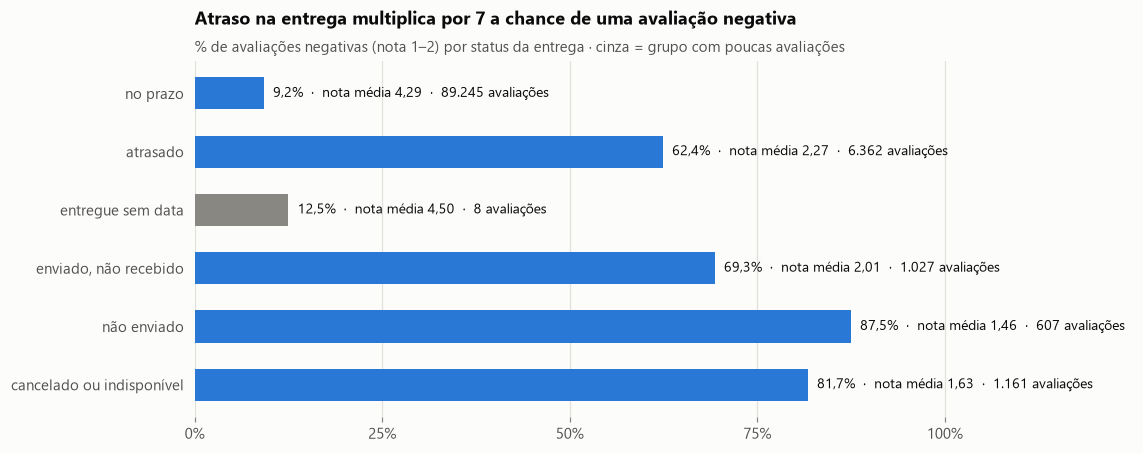

,avaliacoes,nota_media,pct_negativas
delivery_status,,,
no prazo,89245,4.29,9.22
atrasado,6362,2.27,62.42
entregue sem data,8,4.50,12.50
"enviado, não recebido",1027,2.01,69.33
não enviado,607,1.46,87.48
cancelado ou indisponível,1161,1.63,81.74


In [25]:
o = orders.copy()
o["delay_days"] = (o["order_delivered_customer_date"].dt.normalize()
                   - o["order_estimated_delivery_date"].dt.normalize()).dt.days
# Pedidos sem data de entrega: o grupo depende de até onde o pedido avançou no fluxo (seção 8.1)
NO_DATE_GROUP = {"delivered": "entregue sem data", "shipped": "enviado, não recebido",
                 "created": "não enviado", "approved": "não enviado", "processing": "não enviado",
                 "invoiced": "não enviado", "canceled": "cancelado ou indisponível",
                 "unavailable": "cancelado ou indisponível"}
o["delivery_status"] = o["order_status"].map(NO_DATE_GROUP)
o.loc[o["delay_days"] <= 0, "delivery_status"] = "no prazo"
o.loc[o["delay_days"] > 0, "delivery_status"] = "atrasado"
DELIVERY_ORDER = ["no prazo", "atrasado", "entregue sem data", "enviado, não recebido",
                  "não enviado", "cancelado ou indisponível"]

rv = reviews.drop_duplicates("review_id").merge(o, on="order_id", how="left")
rv["negativa"] = rv["review_score"] <= 2

delivery = (rv.groupby("delivery_status")
            .agg(avaliacoes=("review_id", "size"), nota_media=("review_score", "mean"),
                 pct_negativas=("negativa", "mean"))
            .reindex(DELIVERY_ORDER))

fig, ax = plt.subplots(figsize=(11, 4.2))
# "entregue sem data" tem só 8 avaliações: aparece em cinza, como referência, e não como padrão
colors = [MUTED if s == "entregue sem data" else PRIMARY for s in delivery.index[::-1]]
bars = ax.barh(delivery.index[::-1], delivery["pct_negativas"][::-1], height=0.55, color=colors)
for bar, (status, row) in zip(bars, delivery[::-1].iterrows()):
    label = (f"{pct(row['pct_negativas'], 1)}  ·  nota média {row['nota_media']:.2f}".replace(".", ",", 1)
             + f"  ·  {num(row['avaliacoes'])} avaliações")
    ax.annotate(label, (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_title("Atraso na entrega multiplica por 7 a chance de uma avaliação negativa")
subtitle(ax, "% de avaliações negativas (nota 1–2) por status da entrega · cinza = grupo com poucas avaliações")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 1.25)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.spines["bottom"].set_visible(False)
plt.show()
delivery.assign(pct_negativas=delivery["pct_negativas"] * 100)

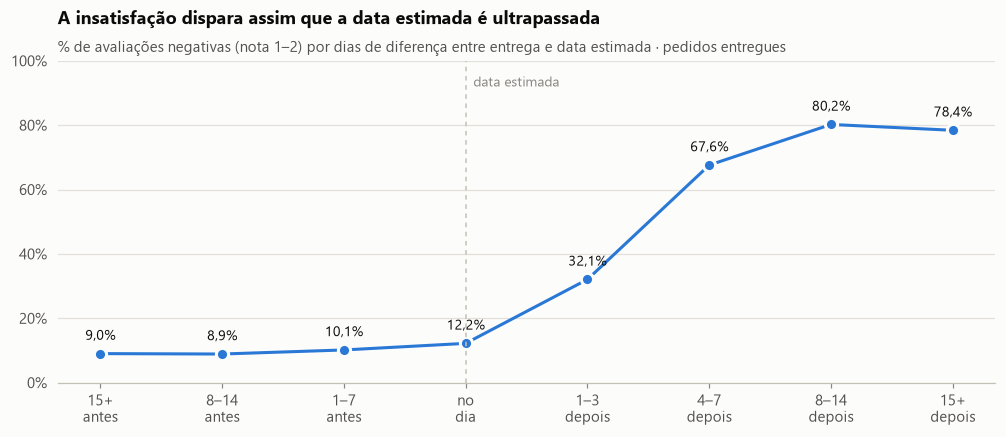

,avaliacoes,pct_negativas
faixa,,
15+ dias antes,34667,9.01
8–14 dias antes,36091,8.88
1–7 dias antes,17216,10.15
no dia,1271,12.20
1–3 dias depois,1843,32.07
4–7 dias depois,1746,67.58
8–14 dias depois,1440,80.21
15+ dias depois,1333,78.39


In [26]:
delivered = rv.dropna(subset=["delay_days"]).copy()
bins = [-1000, -15, -8, -1, 0, 3, 7, 14, 1000]
labels = ["15+ dias antes", "8–14 dias antes", "1–7 dias antes", "no dia", "1–3 dias depois",
          "4–7 dias depois", "8–14 dias depois", "15+ dias depois"]
delivered["faixa"] = pd.cut(delivered["delay_days"], bins=bins, labels=labels)
by_delay = delivered.groupby("faixa", observed=True).agg(
    avaliacoes=("review_id", "size"), pct_negativas=("negativa", "mean"))

fig, ax = plt.subplots(figsize=(11, 3.8))
x = range(len(by_delay))
ax.plot(x, by_delay["pct_negativas"], color=PRIMARY, linewidth=2, marker="o", markersize=8,
        markeredgecolor=SURFACE, markeredgewidth=2)
for i, v in zip(x, by_delay["pct_negativas"]):
    ax.annotate(pct(v, 1), (i, v), xytext=(0, 9), textcoords="offset points", ha="center",
                color=INK, fontsize=9)
ax.axvline(3, color=AXIS, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate("data estimada", (3, 0.92), xytext=(5, 0), textcoords="offset points", color=MUTED, fontsize=9)
ax.set_xticks(list(x), [l.replace(" dias", "").replace(" ", "\n", 1) for l in labels])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("A insatisfação dispara assim que a data estimada é ultrapassada")
subtitle(ax, "% de avaliações negativas (nota 1–2) por dias de diferença entre entrega e data estimada · pedidos entregues")
plt.show()
by_delay.assign(pct_negativas=by_delay["pct_negativas"] * 100)

avaliações
categoria           order_status            
(categoria ausente) delivered           1351
                    shipped               23
                    canceled              14
(pedido sem itens)  unavailable          584
                    canceled             135
                    created                3

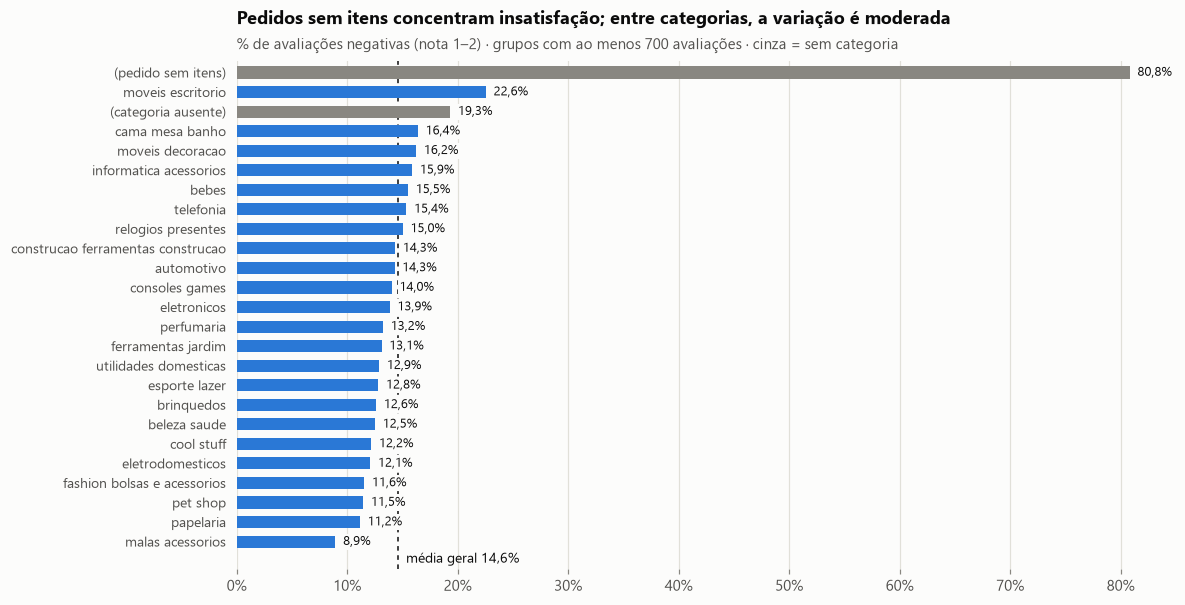

In [27]:
cat = (items.drop_duplicates("order_id")[["order_id", "product_id"]]
       .merge(products[["product_id", "product_category_name"]], on="product_id", how="left"))
rv_cat = rv.merge(cat, on="order_id", how="left")
rv_cat["categoria"] = rv_cat["product_category_name"].str.replace("_", " ")
# "Sem categoria" esconde dois casos distintos: pedidos sem nenhum item e produtos sem categoria.
no_items = ~rv_cat["order_id"].isin(items["order_id"])
rv_cat.loc[no_items, "categoria"] = "(pedido sem itens)"
rv_cat["categoria"] = rv_cat["categoria"].fillna("(categoria ausente)")

display(rv_cat[rv_cat["categoria"].str.startswith("(")]
        .groupby(["categoria", "order_status"]).size().rename("avaliações")
        .groupby(level=0, group_keys=False).nlargest(3).to_frame())

by_cat = (rv_cat.groupby("categoria")
          .agg(avaliacoes=("review_id", "size"), pct_negativas=("negativa", "mean"))
          .query("avaliacoes >= 700")
          .sort_values("pct_negativas"))
base_rate = rv["negativa"].mean()

fig, ax = plt.subplots(figsize=(11, 6))
colors = [MUTED if c.startswith("(") else PRIMARY for c in by_cat.index]
bars = ax.barh(by_cat.index, by_cat["pct_negativas"], height=0.62, color=colors, zorder=2)
ax.axvline(base_rate, color=INK, linewidth=1, linestyle=(0, (3, 3)), zorder=1)
for bar, v in zip(bars, by_cat["pct_negativas"]):
    ax.annotate(pct(v, 1), (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", va="center", color=INK, fontsize=8.5,
                bbox=LABEL_BOX, zorder=3)
ax.annotate(f"média geral {pct(base_rate, 1)}", (base_rate, -0.9), xytext=(5, 0),
            textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_ylim(-1.4, len(by_cat) - 0.4)
ax.set_title("Pedidos sem itens concentram insatisfação; entre categorias, a variação é moderada")
subtitle(ax, "% de avaliações negativas (nota 1–2) · grupos com ao menos 700 avaliações · cinza = sem categoria")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", labelsize=9)
plt.show()

### 9.1 Decisão avaliada: excluir ou manter as avaliações de pedidos sem itens?

O gráfico acima mostra que os pedidos sem itens têm a maior taxa de insatisfação. Mas um pedido sem itens **não tem produto, categoria nem loja** nos metadados, porque o `seller_id` e o `product_id` ficam justamente em `order_items`. Antes de decidir se essas avaliações entram na base, verificamos se o pedido é real e do que os clientes falam.

In [28]:
payments = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
no_items_orders = orders[~orders["order_id"].isin(items["order_id"])]
rv_ni = rv[rv["order_id"].isin(no_items_orders["order_id"])]

def review_text(df):
    text = (df["review_comment_title"].fillna("") + " " + df["review_comment_message"].fillna("")).str.strip().str.lower()
    return text[text != ""]

text_ni, text_all = review_text(rv_ni), review_text(rv)
display(Markdown(
    f"- **{num(len(no_items_orders))} pedidos sem itens**, "
    f"{pct(no_items_orders['order_status'].isin(['unavailable', 'canceled']).sum(), len(no_items_orders))} deles "
    f"`unavailable` ou `canceled`.\n"
    f"- **{pct(no_items_orders['order_id'].isin(payments['order_id']).sum(), len(no_items_orders))} têm pagamento registrado**: "
    f"o pedido existiu e foi pago, só o produto nunca foi separado.\n"
    f"- {num(len(rv_ni))} avaliações ({pct(len(rv_ni), len(rv))} da base), {num(len(text_ni))} com texto, "
    f"**{pct(rv_ni['negativa'].sum(), len(rv_ni))} negativas**."
))

# Temas por expressão regular, comparando com a base inteira
THEMES = {
    "não recebi / não chegou": r"n[aã]o (?:recebi|chegou|foi entregue|entregue|enviad)",
    "estoque / indisponível": r"estoque|indispon|em falta",
    "cancelamento": r"cancel",
    "estorno / reembolso": r"estorn|reembols|dinheiro|devol",
    "falta de resposta / contato": r"respost|contato|atendiment|retorno|e-?mail",
    "cita loja (loja, vendedor, site)": r"\b(?:loja|vendedor|site|empresa)\b",
    "cita loja anonimizada (lannister, stark…)": r"\b(?:lannister|stark|baratheon|targaryen)\b",
}
display(pd.DataFrame({
    "pedidos sem itens (%)": {k: text_ni.str.contains(p).mean() * 100 for k, p in THEMES.items()},
    "base inteira (%)": {k: text_all.str.contains(p).mean() * 100 for k, p in THEMES.items()},
}).rename_axis("% dos comentários que citam"))
text_ni.sample(6, random_state=4).rename("comentários de pedidos sem itens").to_frame()

- **775 pedidos sem itens**, 99,0% deles `unavailable` ou `canceled`.
- **100,0% têm pagamento registrado**: o pedido existiu e foi pago, só o produto nunca foi separado.
- 725 avaliações (0,7% da base), 510 com texto, **80,8% negativas**.

,pedidos sem itens (%),base inteira (%)
% dos comentários que citam,,
não recebi / não chegou,29.61,8.06
estoque / indisponível,18.24,0.48
cancelamento,14.12,1.28
estorno / reembolso,13.33,2.61
falta de resposta / contato,10.98,5.15
"cita loja (loja, vendedor, site)",23.14,10.59
"cita loja anonimizada (lannister, stark…)",13.33,4.60


,comentários de pedidos sem itens
13439,não recomendo o produto me chegou divergindo em relação ao informado no site sobre o funcionamento do mesmo. falta o...
13334,a lojas lannister possui o produto na loja e não quer me enviar e o parceiro targaryen somente depois de dois meses ...
51074,"o produto, me foi prometido a entrega no máximo em 20 de março."
82181,quero o valor de volta
82754,"anúncio ambíguo dá errado lentes de contato são positivas, para hipermetropia, ou negativas, para miopia. tenho hipe..."
69834,a loja me avisou quase no final do prazo que o produt comprado não estava disponível e não seria entregue.


**Leitura**
- **São pedidos reais e pagos**, quase todos de produtos indisponíveis ou cancelados. A falta de itens não é sujeira da base: é a marca de uma venda que **não pôde ser atendida**.
- **Os comentários tratam das falhas mais graves**: não receber, falta de estoque, cancelamento, pedido de estorno e falta de resposta. Todos esses temas aparecem muito acima da média da base.
- **A loja aparece no texto, não nos metadados.** Os comentários citam "loja", "vendedor" ou uma loja anonimizada 2 a 3 vezes mais que a média, mas essas menções são minoria. Além disso, sem `order_items` não há como filtrar esses pedidos por vendedor.

> **Decisão: manter.**
>
> | | Excluir | Manter (escolhida) |
> | --- | --- | --- |
> | Evidência | Perde o tema "vendi sem ter estoque", a falha com maior taxa de insatisfação da base | Preserva relatos de indisponibilidade, cancelamento e reembolso |
> | Metadados | — | Ficam incompletos: sem loja e sem categoria. Recebem a categoria explícita **`sem_itens`**, para não se misturarem com `desconhecida` |
> | Loja | — | Menções a lojas no texto continuam recuperáveis pela busca, como **ganho adicional** |
> | Volume | — | ~0,7% da base, sem impacto no índice |
>
> **O motivo principal não é a loja, e sim a gravidade da evidência.** A ausência de itens limita os **metadados**, mas não invalida o **texto**: o comentário continua sendo o relato de um cliente real sobre um pedido real.

,avaliacoes,pct_negativas
meses de 2016 (fora do gráfico),,
2016-09,4,1.00
2016-10,318,0.29
2016-12,1,0.00


,avaliacoes,pct_negativas
após ago/2018 (fora do gráfico),,
2018-09,10,0.70
2018-10,2,1.00


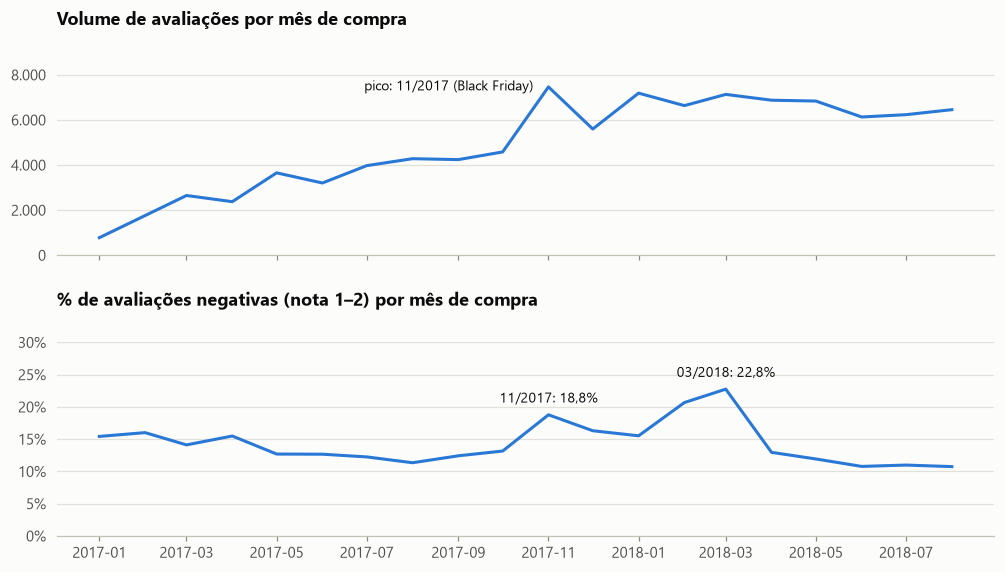

mes,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
avaliacoes,778.00,"1,761.00","2,650.00","2,376.00","3,655.00","3,205.00","3,975.00","4,283.00","4,242.00","4,582.00","7,467.00","5,599.00","7,190.00","6,637.00","7,134.00","6,877.00","6,839.00","6,133.00","6,235.00","6,457.00"
pct_negativas,15.42,16.01,14.11,15.49,12.69,12.67,12.25,11.35,12.42,13.16,18.78,16.31,15.52,20.67,22.75,12.96,11.93,10.78,10.99,10.75


In [29]:
rv["mes"] = rv["order_purchase_timestamp"].dt.to_period("M")
monthly = rv.groupby("mes").agg(avaliacoes=("review_id", "size"), pct_negativas=("negativa", "mean"))
# 2016 tem poucos pedidos e meses sem dados, e set–out/2018 são o corte da base: a série começa em 2017.
display(monthly[monthly.index < pd.Period("2017-01", "M")].rename_axis("meses de 2016 (fora do gráfico)"))
display(monthly[monthly.index > pd.Period("2018-08", "M")].rename_axis("após ago/2018 (fora do gráfico)"))
monthly = monthly[(monthly.index >= pd.Period("2017-01", "M")) & (monthly.index <= pd.Period("2018-08", "M"))]
x = monthly.index.to_timestamp()

fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"hspace": 0.45})
ax = axes[0]
ax.plot(x, monthly["avaliacoes"], color=PRIMARY, linewidth=2)
ax.set_title("Volume de avaliações por mês de compra")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: num(v)))
peak = monthly["avaliacoes"].idxmax()
ax.annotate(f"pico: {peak.strftime('%m/%Y')} (Black Friday)", (peak.to_timestamp(), monthly["avaliacoes"].max()),
            xytext=(-10, 0), textcoords="offset points", ha="right", va="center", color=INK, fontsize=9)
ax.set_ylim(0, monthly["avaliacoes"].max() * 1.15)

ax = axes[1]
ax.plot(x, monthly["pct_negativas"], color=PRIMARY, linewidth=2)
for p in [pd.Period("2017-11", "M"), pd.Period("2018-03", "M")]:
    v = monthly.loc[p, "pct_negativas"]
    ax.annotate(f"{p.strftime('%m/%Y')}: {pct(v, 1)}", (p.to_timestamp(), v), xytext=(0, 8),
                textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_title("% de avaliações negativas (nota 1–2) por mês de compra")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.3)
plt.show()
monthly.assign(pct_negativas=monthly["pct_negativas"] * 100).T

**Leitura**
- **A entrega é o metadado mais discriminante da base.**
  - Entregas no prazo têm cerca de 9% de avaliações negativas, e atrasadas, cerca de 62%.
  - Entre os pedidos que **não chegaram ao cliente**, a insatisfação cresce quanto mais cedo o fluxo travou: cerca de 69% nos enviados e não recebidos, 82% nos cancelados ou indisponíveis e 88% nos que nem saíram do vendedor. Um cliente que nunca viu o pedido sair parece mais frustrado do que um que sabe que ele está com a transportadora.
  - Os 8 pedidos entregues sem data têm nota média alta, o que confirma que foram de fato entregues.
  - A curva por dias de atraso mostra o efeito começando já no primeiro dia após a data estimada, o que sugere que o cliente julga pela **promessa** de prazo, e não pelo prazo absoluto.
- **"Sem categoria" escondia dois fenômenos diferentes.**
  - Os **pedidos sem nenhum item**, quase todos indisponíveis ou cancelados, têm a maior taxa de insatisfação da base. Nesses casos, o cliente nem chegou a receber um produto.
  - Já os produtos que apenas não têm categoria ficam próximos da média.
  - Tratar os dois como "desconhecida" misturaria esses perfis.
- **Entre as categorias reais, a variação é moderada.** O destaque negativo é móveis de escritório. A categoria é útil para perguntas segmentadas ("o que reclamam em móveis?").
- **O volume cresce ao longo de 2017**, com pico em novembro (Black Friday).
  - A taxa de negativas sobe nesse pico e volta a subir em fevereiro–março de 2018, o que é coerente com pressão logística em períodos de alta demanda.
  - 2016 e os meses após agosto de 2018 foram excluídos do gráfico por terem poucas avaliações.

> **Implicação para o projeto**
> - Os metadados que vão para o índice vetorial são: **status da entrega** (`no_prazo` / `atrasado` / `entregue_sem_data` / `enviado_nao_recebido` / `nao_enviado` / `cancelado_indisponivel`), **dias de atraso**, **status do pedido**, **nota**, **sentimento derivado da nota** (negativo 1–2, neutro 3, positivo 4–5), **categoria** e **data**.
> - Pedidos sem itens recebem a categoria explícita `sem_itens`, separada de `desconhecida`.
> - Eles justificam filtros como "reclamações de clientes com entrega atrasada", que estreitam a busca para o subconjunto onde a evidência de fato está.
> - Esta análise é **descritiva**. Ela mostra associação, não causalidade.

## 10. Decisões para a preparação da base

| # | Achado | Decisão |
| --- | --- | --- |
| 1 | Só ~43% das avaliações têm texto; ~1,7 mil (4% das com texto) têm apenas título | Documento = **título + comentário**; entra quem tiver qualquer um dos dois. **Avaliamos excluir os só-título e decidimos manter** (seção 2.1) |
| 2 | Negativas estão sobrerrepresentadas entre as que comentam | Respostas **não extrapolam** proporções dos comentários para a base inteira |
| 3 | Comentários curtos (mediana ~53 caracteres) e truncados em ~200 na origem | **Sem chunking**: uma avaliação = um documento. O truncamento é declarado como limitação |
| 4 | Ruído superficial (quebras de linha, pontuação repetida) | **Limpeza leve** do texto indexado, preservando acentos, caixa e emojis |
| 5 | Cerca de 1 em cada 5 comentários é cópia de outro | **Manter na base** (são clientes distintos); **deduplicar na seleção** das evidências |
| 6 | Grafias variam em acento, caixa e pontuação ("Ótimo", "otimo", "ÓTIMO!") | Comparação de textos com **normalização de comparação**: minúsculas, sem acentos, sem pontuação |
| 7 | Comentários sem conteúdo (".", "ok") | Marcar como baixa informação, com limiar a definir no preparo |
| 8 | Nomes de lojas anonimizados ("lannister", "stark"…) | Manter no texto; o prompt explica que são **pseudônimos de lojas** |
| 9 | "nao" é o termo mais discriminante das negativas | **Negações nunca são removidas**, nem como *stopword* |
| 10 | TF-IDF não captura sentido ("recebi" ≈ "não recebi") | **Busca por embeddings densos**; BoW/TF-IDF ficam na análise exploratória e o BM25 é candidato à busca híbrida na fase 2 |
| 11 | `review_id` repetido em pedidos diferentes | **Uma linha por `review_id`**, que é o identificador da evidência |
| 12 | Pedidos sem itens (81% negativas, todos pagos) ≠ produtos sem categoria | **Avaliamos excluir e decidimos manter** (seção 9.1): o texto é evidência das falhas mais graves. Junções com `left join`; categorias explícitas **`sem_itens`** e **`desconhecida`** |
| 13 | Pedido sem data de entrega reúne situações distintas, inclusive pedidos entregues | **Status da entrega por etapa do fluxo**: `entregue_sem_data`, `enviado_nao_recebido`, `nao_enviado`, `cancelado_indisponivel` (seção 8.1) |
| 14 | Entrega é o metadado que mais separa satisfeitos de insatisfeitos | Metadados: **status e atraso da entrega**, status do pedido, nota, sentimento, categoria, data |

### Técnicas de processamento de texto: o que usamos, onde e por quê

Um mesmo comentário passa por **dois tratamentos diferentes**, conforme o objetivo:

```
                ┌─► normalização de comparação ─► contar duplicatas, BoW, TF-IDF   (análise)
comentário ─────┤     minúsculas · sem acentos · sem pontuação · sem stopwords
                └─► limpeza leve ─────────────► embeddings E5 ─► índice vetorial (busca do RAG)
                      espaços · quebras de linha · pontuação repetida
                      (mantém caixa, acentos, emojis e negações)
```

| Técnica | Usamos? | Onde | Por quê |
| --- | --- | --- | --- |
| Minúsculas (*case folding*) | Sim | Só na comparação e na análise | "Ótimo" e "ótimo" contam como o mesmo texto. No índice, a caixa fica: "PÉSSIMO" carrega intensidade |
| Remoção de acentos (Unicode NFKD) | Sim | Só na comparação e na análise | "ótimo" e "otimo" aparecem quase na mesma proporção. No índice, os acentos ficam, porque o E5 foi treinado com texto acentuado |
| Remoção de pontuação e colapso de espaços (regex) | Sim | Comparação, análise e (só o excesso) no índice | Ruído superficial |
| Tokenização por palavras | Sim | Contagem de palavras, BoW e TF-IDF | Unidade das contagens |
| Tokenização por subpalavras (*WordPiece/SentencePiece*) | Sim | Embeddings | Feita pelo próprio tokenizador do E5; lida com erros de digitação e palavras raras |
| ***Bag of Words*** | Sim | Análise exploratória (seção 6) | Termos mais frequentes por grupo: simples e transparente |
| **TF-IDF** | Sim | Análise exploratória (seção 6) | Termos característicos de cada grupo, descontando os que são comuns a todos |
| N-gramas (bigramas) | Sim | BoW e TF-IDF | Capturam expressões como "nao recebi" e "antes prazo" |
| Remoção de *stopwords* | Só no BoW e no TF-IDF, com lista própria | Análise exploratória | Tira palavras vazias das contagens. Negações ficam: listas prontas removeriam o "não" |
| *Stemming* / lematização | Não | — | Pouco ganho em textos curtos, termos menos legíveis, e os embeddings já tratam variações de palavra |
| Similaridade de cosseno | Sim | Teste do TF-IDF (seção 6.2) e busca vetorial | Medida de proximidade entre vetores de texto |
| **Embeddings densos** (`multilingual-e5-base`) | Sim | Busca do RAG | Representam o sentido: "não recebi" ≈ "não chegou", e a negação muda o vetor |
| BM25 (busca lexical) | Fase 2 | Busca híbrida | Complementa os embeddings em termos exatos ("lannister", categorias) |

**Próxima etapa:** implementar essas decisões num módulo de preparo reprodutível (`src/preprocessing.py`), que gera a base de documentos do RAG.